# 02. The stock side of the data

Notebook 01 looked at managers. Here we look at **stocks**: how widely each is held, how concentrated the money is, how many "stocks" are really funds, and why raw shared-holder counts need a correction.

One stock = one issuer, identified by the first six CUSIP characters (this merges share classes). Money uses the cleaned values, without the filers flagged as unreliable. Links count every filer.

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))   # shared helpers from src
import gutils as gl
from config import INTERIM, MAIN_QUARTER

FIGURES = ROOT / "figures"
BLUE, MUTED, GRID, INK, SOFT, ORANGE = "#2a78d6", "#b9b7ae", "#e6e5df", "#0b0b0b", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": MUTED, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.titleweight": "bold", "text.color": INK, "axes.labelcolor": SOFT,
    "xtick.color": SOFT, "ytick.color": SOFT, "xtick.bottom": False, "ytick.left": False,
})
pd.set_option("display.width", 200, "display.max_colwidth", 40)

h = pd.read_parquet(INTERIM / f"holdings_{MAIN_QUARTER}.parquet", columns=["CIK", "NAMEOFISSUER", "CUSIP", "VALUE", "VALUE_RELIABLE"])
h["ISSUER"] = h["CUSIP"].str[:6]
h["V"] = h["VALUE"].where(h["VALUE_RELIABLE"], 0)
pos = h.groupby(["CIK", "ISSUER"], as_index=False).agg(V=("V", "sum"))
stocks = pos.groupby("ISSUER").agg(value=("V", "sum"), holders=("CIK", "nunique"))
stocks["name"] = h.groupby("ISSUER")["NAMEOFISSUER"].agg(lambda s: s.value_counts().index[0])
stocks = stocks.sort_values("value", ascending=False)
stocks["rank"] = np.arange(1, len(stocks) + 1)
managers = pos["CIK"].nunique()
print(f"{MAIN_QUARTER}: {len(stocks):,} issuers, {managers:,} managers, {len(pos):,} manager-stock links")
print("Managers flagged as unreliable on value (links kept):", int((~h.drop_duplicates('CIK').set_index('CIK')['VALUE_RELIABLE']).sum()))
stocks.head(5)

2026Q2: 12,713 issuers, 8,737 managers, 1,991,944 manager-stock links
Managers flagged as unreliable on value (links kept): 188


,value,holders,name,rank
ISSUER,,,,
67066G,3.214557e+12,5955,NVIDIA CORPORATION,1
02079K,2.764773e+12,6271,ALPHABET INC,2
037833,2.695459e+12,6107,APPLE INC,3
594918,1.966423e+12,6211,MICROSOFT CORP,4
464287,1.942947e+12,5752,ISHARES TR,5


## 1. How widely is each stock held?

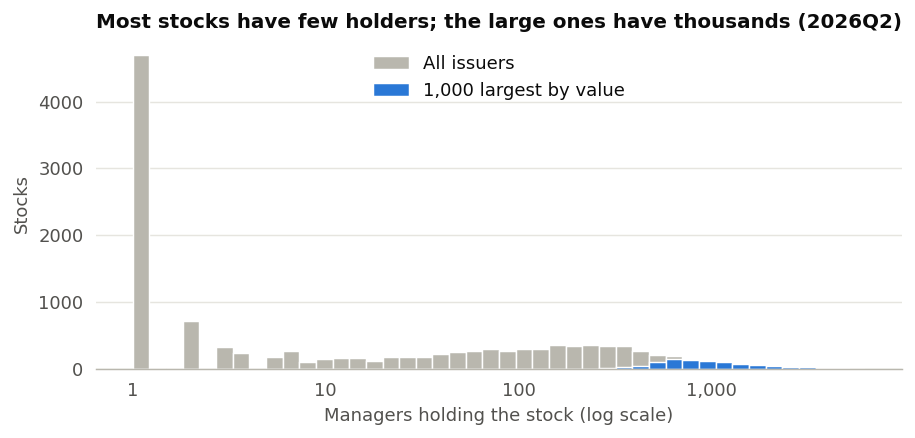

Holders per stock, all issuers: median 7  p90 407  max 6271
Holders per stock, top 1,000 by value: median 878  min 1  max 6271
Issuers with a single holder: 4702 of 12713


In [2]:
top = stocks.head(1000)
fig, ax = plt.subplots(figsize=(8, 3.3))
bins = np.logspace(0, np.log10(stocks["holders"].max()), 45)
ax.hist(stocks["holders"], bins=bins, color=MUTED, edgecolor="white", linewidth=0.8, label="All issuers")
ax.hist(top["holders"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.8, label="1,000 largest by value")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Managers holding the stock (log scale)")
ax.set_ylabel("Stocks")
ax.legend(frameon=False, loc="upper center")
ax.set_title(f"Most stocks have few holders; the large ones have thousands ({MAIN_QUARTER})")
fig.savefig(FIGURES / "eda_holders_per_stock.png")
plt.show()
print("Holders per stock, all issuers: median", int(stocks["holders"].median()), " p90", int(stocks["holders"].quantile(.9)), " max", int(stocks["holders"].max()))
print("Holders per stock, top 1,000 by value: median", int(top["holders"].median()), " min", int(top["holders"].min()), " max", int(top["holders"].max()))
print("Issuers with a single holder:", int((stocks["holders"] == 1).sum()), "of", len(stocks))

## 2. How concentrated is the money?
If a few hundred stocks hold almost all the money, cutting to the largest 1,000 loses little. If not, the cut is a real choice.

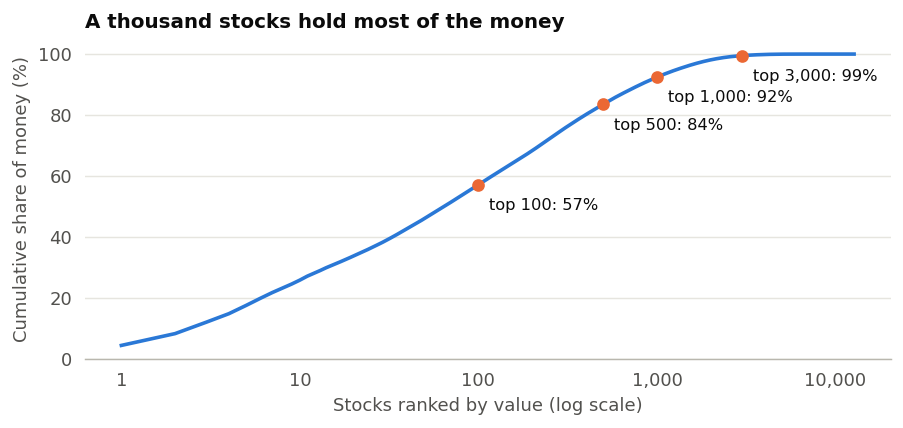

{'top 100': np.float64(57.2), 'top 500': np.float64(83.5), 'top 1000': np.float64(92.4), 'top 3000': np.float64(99.5)}
Holders of the 1,000th stock: 611 ; of the 3,000th: 107


In [3]:
cum = stocks["value"].cumsum() / stocks["value"].sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(stocks["rank"], cum * 100, color=BLUE, lw=2)
ax.set_xscale("log")
ax.set_ylim(0, 105)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Stocks ranked by value (log scale)")
ax.set_ylabel("Cumulative share of money (%)")
marks = [100, 500, 1000, 3000]
for r in marks:
    ax.plot(r, cum.iloc[r - 1] * 100, "o", color=ORANGE, ms=6)
    ax.annotate(f"top {r:,}: {cum.iloc[r - 1] * 100:.0f}%", (r, cum.iloc[r - 1] * 100), xytext=(6, -14), textcoords="offset points", fontsize=9)
ax.set_title("A thousand stocks hold most of the money")
fig.savefig(FIGURES / "eda_value_concentration.png")
plt.show()
print({f"top {r}": round(cum.iloc[r - 1] * 100, 1) for r in marks})
print("Holders of the 1,000th stock:", int(stocks.iloc[999]["holders"]), "; of the 3,000th:", int(stocks.iloc[2999]["holders"]))

## 3. How many of the largest "stocks" are funds?
Filter 6 removes ETFs and funds. The sector mapping (script s02) now gives a proper fund flag (column is_fund in issuer_map.parquet). This cell keeps the earlier **name-based proxy** for comparison (names containing iShares, SPDR, Vanguard, ETF and similar). It misses funds with plain names and could catch a few companies, so treat the numbers as approximate.

In [4]:
FUND = re.compile(r"\b(ETF|ETN|ISHARES|SPDR|VANGUARD|PROSHARES|WISDOMTREE|DIREXION|SELECT SECTOR|SCHWAB STRATEGIC|DIMENSIONAL|"
                  r"GRAYSCALE|INVESCO QQQ|FIRST TR|GLOBAL X|VANECK|ARK|FD|FUNDS?)\b", re.I)
stocks["fund_like"] = stocks["name"].str.contains(FUND)
t = stocks.head(1000)
print(f"Top 1,000 by value: {t['fund_like'].sum()} fund-like names ({t['fund_like'].mean() * 100:.1f}% of stocks, {t.loc[t['fund_like'], 'value'].sum() / t['value'].sum() * 100:.1f}% of their value)")
print("Top 200:", int(stocks.head(200)["fund_like"].sum()), "fund-like; top 500:", int(stocks.head(500)["fund_like"].sum()))
print("Largest fund-like names:", t[t["fund_like"]]["name"].head(12).tolist())
print("Largest others (sanity check, should be companies):", t[~t["fund_like"]]["name"].head(12).tolist())
print("Fund-like holders per stock, median:", int(t.loc[t["fund_like"], "holders"].median()), "vs others:", int(t.loc[~t["fund_like"], "holders"].median()))

Top 1,000 by value: 76 fund-like names (7.6% of stocks, 12.4% of their value)
Top 200: 25 fund-like; top 500: 46
Largest fund-like names: ['ISHARES TR', 'VANGUARD INDEX FDS', 'STATE STR SPDR S&P 500 ETF T', 'SPDR SERIES TRUST', 'ISHARES TR', 'SCHWAB STRATEGIC TR', 'ISHARES TR', 'SELECT SECTOR SPDR TR', 'DIMENSIONAL ETF TRUST', 'VANGUARD SCOTTSDALE FDS', 'ISHARES INC', 'INVESCO QQQ TR']
Largest others (sanity check, should be companies): ['NVIDIA CORPORATION', 'ALPHABET INC', 'APPLE INC', 'MICROSOFT CORP', 'AMAZON COM INC', 'BROADCOM INC', 'MICRON TECHNOLOGY INC', 'ELI LILLY & CO', 'META PLATFORMS INC', 'TESLA INC', 'ADVANCED MICRO DEVICES INC', 'JPMORGAN CHASE & CO']
Fund-like holders per stock, median: 1601 vs others: 850


C:\Users\izang\AppData\Local\Temp\ipykernel_17784\2040849014.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  stocks["fund_like"] = stocks["name"].str.contains(FUND)


## 4. Why raw shared-holder counts are not enough
Two stocks that many managers hold will share many managers **by chance alone**. For the 1,000 largest stocks and all managers, compare each pair's actual shared holders with the number expected if managers picked stocks independently: `holders_A x holders_B / managers`.

The **z-score** asks how far the actual count is above that expectation, in standard deviations. Popularity alone should give a z-score near zero.

Managers in this graph: 8,432. Pairs of stocks: 499,500
Pairs sharing at least 1 / 10 / 100 holders: ['99.8%', '99.8%', '99.1%']


Spearman correlation, shared holders vs expected-by-popularity: 0.855
Spearman correlation, z-score vs expected-by-popularity: -0.202
Top 5,000 pairs by raw shared holders: both stocks among the 50 most-held 24%, at least one 91%
Top 5,000 pairs by z-score:            both stocks among the 50 most-held 4%, at least one 5%


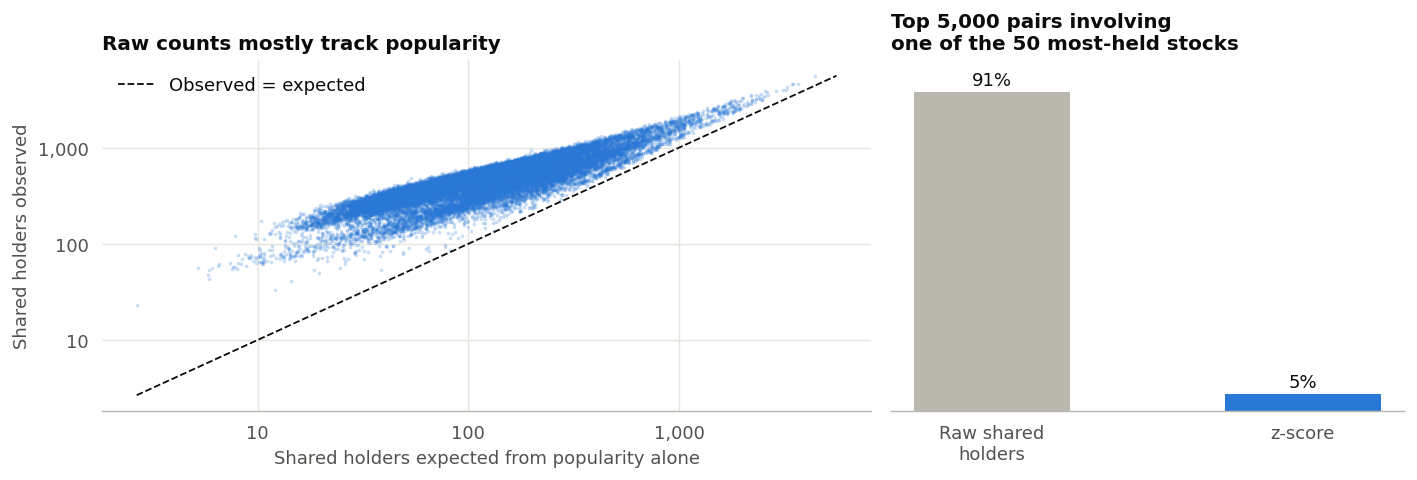

In [5]:
uni = stocks.head(1000)
p = pos[pos["ISSUER"].isin(uni.index)][["CIK", "ISSUER"]]
C, z, k, m = gl.shared_holder_z(p, uni)
iu = np.triu_indices(len(uni), 1)
obs, zz = C[iu], z[iu]
exp = (np.outer(k, k) / m)[iu]
print(f"Managers in this graph: {m:,}. Pairs of stocks: {len(obs):,}")
print("Pairs sharing at least 1 / 10 / 100 holders:", [f"{(obs >= n).mean() * 100:.1f}%" for n in (1, 10, 100)])
print("Spearman correlation, shared holders vs expected-by-popularity:", round(pd.Series(obs).corr(pd.Series(exp), method="spearman"), 3))
print("Spearman correlation, z-score vs expected-by-popularity:", round(pd.Series(zz).corr(pd.Series(exp), method="spearman"), 3))

popular = set(np.argsort(-k)[:50])
def popular_share(score, n=5000):
    idx = np.argsort(-score)[:n]
    rows, cols = iu[0][idx], iu[1][idx]
    return np.mean([(a in popular) and (b in popular) for a, b in zip(rows, cols)]) * 100, np.mean([(a in popular) or (b in popular) for a, b in zip(rows, cols)]) * 100
raw_both, raw_any = popular_share(obs)
z_both, z_any = popular_share(zz)
print(f"Top 5,000 pairs by raw shared holders: both stocks among the 50 most-held {raw_both:.0f}%, at least one {raw_any:.0f}%")
print(f"Top 5,000 pairs by z-score:            both stocks among the 50 most-held {z_both:.0f}%, at least one {z_any:.0f}%")

rng = np.random.default_rng(42)
pick = rng.choice(len(obs), 25000, replace=False)
pick = pick[obs[pick] > 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.scatter(exp[pick], obs[pick], s=4, color=BLUE, alpha=0.25, linewidths=0)
lims = [min(exp[pick].min(), obs[pick].min()), max(exp[pick].max(), obs[pick].max())]
ax.plot(lims, lims, color=INK, lw=1, ls="--", label="Observed = expected")
ax.legend(frameon=False, loc="upper left")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Shared holders expected from popularity alone")
ax.set_ylabel("Shared holders observed")
ax.grid(axis="x", color=GRID)
ax.set_title("Raw counts mostly track popularity")
ax = axes[1]
labels = ["Raw shared\nholders", "z-score"]
vals = [raw_any, z_any]
ax.bar(labels, vals, color=[MUTED, BLUE], width=0.5)
for i, v in enumerate(vals):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=10)
ax.set_ylim(0, 100)
ax.grid(False); ax.set_yticks([]); ax.spines["bottom"].set_visible(True)
ax.set_title("Top 5,000 pairs involving\none of the 50 most-held stocks")
fig.tight_layout()
fig.savefig(FIGURES / "eda_popularity_confound.png")
plt.show()